# Phân tích khám phá (EDA) — AQI & Thời tiết

Notebook này đọc file `data/processed/aqi_weather_features.csv` (tạo bởi pipeline `collect → clean → features`)
và vẽ nhanh các biểu đồ kiểm tra chất lượng dữ liệu.

**Chạy notebook:** mở thư mục gốc project rồi chạy `jupyter notebook`.
Nếu chưa có dữ liệu, chạy `python scripts/make_demo_data.py`, `python -m src.clean`, `python -m src.features` trước.

In [1]:
import pandas as pd
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

# Tải dữ liệu
df = pd.read_csv('../data/processed/aqi_weather_features.csv', parse_dates=['datetime_local'])

print(f"Tổng số dòng: {len(df)}")
print(f"Các thành phố: {sorted(df['city'].unique())}")
print(f"Khoảng thời gian: {df['datetime_local'].min()} đến {df['datetime_local'].max()}")

# Hiển thị 5 dòng đầu
df.head()

Tổng số dòng: 8731
Các thành phố: ['Bangkok', 'Hanoi', 'HoChiMinh', 'Jakarta']
Khoảng thời gian: 2025-10-01 07:00:00 đến 2026-01-01 05:00:00


,datetime_utc,no2,o3,pm10,pm25,city,temp_c,humidity,wind_speed,precip_mm,...,AQI_Level,Wind_Category,Temp_Category,Weather_Category,datetime_local,Hour,DayOfWeek,IsWeekend,AQI_Rolling_24h,Weather_Impact
0,2025-10-01 00:00:00+00:00,0.017,0.002,15.0,12.150000,Bangkok,25.6,93,2.15,0.4,...,Moderate,Calm,Normal,Rainy,2025-10-01 07:00:00,7,Wednesday,False,NaN,0.0
1,2025-10-01 01:00:00+00:00,0.016,0.002,16.0,12.366667,Bangkok,26.6,91,1.80,0.0,...,Moderate,Calm,Normal,Dry,2025-10-01 08:00:00,8,Wednesday,False,NaN,0.0
2,2025-10-01 02:00:00+00:00,0.015,0.003,16.0,12.700000,Bangkok,28.5,79,2.33,0.0,...,Moderate,Calm,Normal,Dry,2025-10-01 09:00:00,9,Wednesday,False,NaN,0.0
3,2025-10-01 03:00:00+00:00,0.013,0.005,17.0,13.050000,Bangkok,28.9,73,2.67,0.2,...,Moderate,Calm,Normal,Rainy,2025-10-01 10:00:00,10,Wednesday,False,NaN,0.0
4,2025-10-01 04:00:00+00:00,0.009,0.009,18.0,13.383333,Bangkok,29.6,72,1.25,0.0,...,Moderate,Calm,Normal,Dry,2025-10-01 11:00:00,11,Wednesday,False,NaN,0.0


In [2]:
# Tính count, mean, max, min và sắp xếp giảm dần theo mean
city_stats = df.groupby('city')['AQI'].agg(['count', 'mean', 'max', 'min']).round(1).sort_values('mean', ascending=False)
display(city_stats)

,count,mean,max,min
city,,,,
HoChiMinh,2193,105.9,184.3,8.6
Bangkok,1266,98.6,156.7,54.0
Jakarta,1905,98.5,189.2,4.9
Hanoi,1259,81.5,168.0,15.4


In [3]:
# Lấy mẫu mỗi 6 giờ cho mỗi thành phố để biểu đồ nhẹ và không bị chồng chéo
sample = df[df.groupby('city').cumcount() % 6 == 0].copy()

fig = px.line(
    sample, 
    x='datetime_local', 
    y='AQI_Rolling_24h', 
    color='city',
    title='AQI trung bình trượt 24 giờ theo thời gian',
    labels={'datetime_local': 'Thời gian', 'AQI_Rolling_24h': 'AQI (TB 24h)', 'city': 'Thành phố'}
)
fig.show()

In [4]:
fig = px.bar(
    city_stats.reset_index(), 
    x='city', 
    y='mean', 
    color='city',
    title='AQI trung bình theo thành phố',
    labels={'city': 'Thành phố', 'mean': 'AQI trung bình'}
)
fig.show()

In [6]:
# Lấy mẫu tối đa 5000 điểm để trình duyệt không bị lag
scatter_df = df.dropna(subset=['wind_speed', 'AQI']).sample(n=min(5000, len(df)), random_state=42)

fig = px.scatter(
    scatter_df, 
    x='wind_speed', 
    y='AQI', 
    color='city', 
    opacity=0.4,
    title='Tốc độ gió và AQI',
    labels={'wind_speed': 'Tốc độ gió (m/s)', 'AQI': 'AQI', 'city': 'Thành phố'}
)
fig.show()

In [7]:
# Pivot table và đảm bảo cột giờ được sắp xếp từ 0 đến 23
pv = df.pivot_table(index='city', columns='Hour', values='AQI', aggfunc='mean')
pv = pv.reindex(columns=sorted(pv.columns))

fig = px.imshow(
    pv, 
    aspect='auto', 
    title='AQI trung bình theo giờ trong ngày và thành phố',
    labels={'x': 'Giờ trong ngày', 'y': 'اThành phố', 'color': 'AQI TB'}
)
fig.show()

In [8]:
# Ép thứ tự hiển thị là Dry trước, Rainy sau cho đúng logic báo cáo
df_plot = df.copy()
df_plot['Weather_Category'] = pd.Categorical(df_plot['Weather_Category'], categories=['Dry', 'Rainy'], ordered=True)

fig = px.box(
    df_plot, 
    x='Weather_Category', 
    y='AQI', 
    color='Weather_Category',
    title='Phân bố AQI theo loại thời tiết (Dry vs Rainy)',
    labels={'Weather_Category': 'Loại thời tiết', 'AQI': 'Chỉ số AQI'}
)
fig.show()

# IN SỐ LIỆU ĐỂ ĐIỀN VÀO BÁO CÁO (Mục 5.6 và 5.7)
print("\n" + "="*50)
print("SỐ LIỆU CHO BÁO CÁO (Mục 5.6 & 5.7):")
print("="*50)
weather_stats = df_plot.groupby('Weather_Category')['AQI'].agg(['mean', 'count']).round(1)
print(weather_stats)
drop_pct = ((weather_stats.loc['Dry', 'mean'] - weather_stats.loc['Rainy', 'mean']) / weather_stats.loc['Dry', 'mean'] * 100).round(1)
print(f"-> Mức giảm AQI khi có mưa: {drop_pct}%")


SỐ LIỆU CHO BÁO CÁO (Mục 5.6 & 5.7):
                  mean  count
Weather_Category             
Dry               99.5   5555
Rainy             88.8   1068
-> Mức giảm AQI khi có mưa: 10.8%


In [9]:
print("="*60)
print("PHÂN TÍCH BỔ SUNG CHO MỤC 5.7")
print("="*60)

# 1. Phân bố EPA
print("\n1. Phân bố mức AQI theo EPA (%):")
aqi_dist = df['AQI_Level'].value_counts(normalize=True).sort_index() * 100
print(aqi_dist.round(1).to_string())

# 2. Ma trận tương quan (Khớp với Bảng 6 trong báo cáo)
print("\n2. Ma trận tương quan Pearson với AQI:")
cols = ['AQI', 'pm25', 'pm10', 'no2', 'wind_speed', 'precip_mm']
corr = df[cols].corr()['AQI'].drop('AQI').round(2)
counts = df[cols].count().drop('AQI')
for col in corr.index:
    print(f"{col:12} | r = {corr[col]:>5} | n = {counts[col]}")

# 3. Ngày thường vs Cuối tuần
print("\n3. So sánh AQI: Ngày thường vs Cuối tuần:")
week_stats = df.groupby('IsWeekend')['AQI'].mean().round(1)
print(f"Ngày thường (IsWeekend=False): {week_stats[False]}")
print(f"Cuối tuần (IsWeekend=True)   : {week_stats[True]}")
print(f"-> Chênh lệch: {week_stats[True] - week_stats[False]} điểm")

PHÂN TÍCH BỔ SUNG CHO MỤC 5.7

1. Phân bố mức AQI theo EPA (%):
AQI_Level
Good                               4.1
Moderate                          54.9
Unhealthy                          9.0
Unhealthy for Sensitive Groups    32.0

2. Ma trận tương quan Pearson với AQI:
pm25         | r =  0.98 | n = 6623
pm10         | r =  0.71 | n = 1946
no2          | r = -0.32 | n = 1922
wind_speed   | r = -0.35 | n = 8731
precip_mm    | r = -0.07 | n = 8731

3. So sánh AQI: Ngày thường vs Cuối tuần:
Ngày thường (IsWeekend=False): 96.2
Cuối tuần (IsWeekend=True)   : 101.9
-> Chênh lệch: 5.700000000000003 điểm


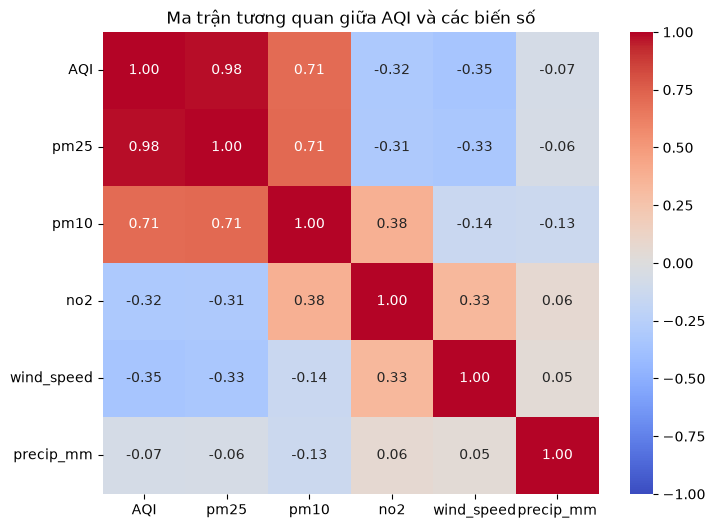

In [10]:
# Vẽ ma trận tương quan bằng Seaborn (đẹp hơn để chụp ảnh cho báo cáo nếu cần)
plt.figure(figsize=(8, 6))
sns.heatmap(df[cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Ma trận tương quan giữa AQI và các biến số')
plt.show()

# Vẽ biểu đồ so sánh cuối tuần
fig_weekend = px.box(
    df, 
    x='IsWeekend', 
    y='AQI', 
    color='IsWeekend',
    title='So sánh AQI: Ngày thường (False) vs Cuối tuần (True)',
    labels={'IsWeekend': 'Là cuối tuần?', 'AQI': 'AQI'}
)
fig_weekend.update_xaxes(ticktext=['Ngày thường', 'Cuối tuần'], tickvals=[False, True])
fig_weekend.show()